# Cheap test-time defenses, tested against fixed **and adaptive** perturbations

Main budget ε = 10/255 (secondary check: the fixed ε = 8/255 perturbation). Every defense is applied to the **8-bit perturbed image** before or inside the standard SmolVLM-256M pipeline.

| Defense | Where it acts | Idea |
|---|---|---|
| none (splitting off / on) | — | references |
| JPEG (quality 75) | whole image | compression removes fine noise |
| Gaussian blur (σ = 1) | whole image | smooths high frequencies |
| Random resize-and-pad | whole image | v no longer lines up with the pixels it was built for |
| **Global tile: random resize-and-pad** | only the global tile (splitting on) | from notebook 03, part D: the attack lives in the global tile; local tiles keep the detail |
| **Global tile: blanked** | only the global tile (splitting on) | the model answers from the 16 local tiles alone |

For each defense we measure:
- **Clean cost:** how often the defense alone changes the clean caption (a defense that ruins clean answers is useless).
- **Fixed v:** the perturbation from notebook 01, unaware of the defense.
- **Adaptive v:** a new perturbation computed *through* the defense (JPEG: straight-through gradient; random transforms: averaged over random draws; global-tile defenses: the attacker also targets the local tiles). Starts from the fixed v. **This is the number that decides whether a defense is real.**

Attack success is always measured against the defended clean caption.

**Resumable:** adaptive perturbations and finished rows are saved to Drive; `Run all` again after a disconnect skips them.
**Rough estimate:** 90–120 min in total (about 45–60 min of adaptive training).
**Outputs:** the training logs (section 5), the results table (section 7) and the figure (section 8), saved to `test_time_defenses_results.json` and `test_time_defenses.png`.

## 1. Configuration

In [1]:
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
N_BUILD    = 500
N_EVAL_OFF = 200          # eval images for defenses with splitting off
N_EVAL_ON  = 100          # eval images for defenses with splitting on (17 tiles: slower)
OUT_DIR    = "/content/drive/MyDrive/uap_smolvlm"
V10_PATH   = OUT_DIR + "/uap_smolvlm256m_linf10.npy"
V8_PATH    = OUT_DIR + "/uap_smolvlm256m_linf8.npy"
XI         = 10/255
ADAPT_EPOCHS      = 4     # whole-image defenses (warm start from the fixed v)
TILE_ADAPT_EPOCHS = 3     # global-tile defenses (each step processes several tiles)
LOCAL_TILES_PER_STEP = 3  # local tiles sampled per image per step (of 16)
JPEG_Q     = 75
BLUR_SIGMA = 1.0
RRP_MIN    = 0.8          # random resize to s in [0.8, 1.0] of the image size, then pad back to 512
CAPTION_SIM_CHANGED = 0.5
MAX_NEW_TOKENS = 40
P_DESCRIBE = "Describe this image in one sentence."
SEED = 0

## 2. Setup, data, model

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile, io
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
load = lambda fs: torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(fs, desc="decoding")])
B_u8 = load([FILES[i] for i in perm[:N_BUILD]])
E_u8 = load([FILES[i] for i in perm[N_BUILD:N_BUILD + N_EVAL_OFF]])

from transformers import AutoProcessor, AutoModelForImageTextToText
processor = AutoProcessor.from_pretrained(MODEL_ID); processor.tokenizer.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
for p in model.parameters(): p.requires_grad_(False)
VIS = model.model.vision_model
ip = processor.image_processor
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)

V10 = torch.from_numpy(np.load(V10_PATH).copy()).float()
V8  = torch.from_numpy(np.load(V8_PATH).copy()).float()
torch.manual_seed(SEED); RAND10 = XI * torch.sign(torch.randn_like(V10))

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()
def changed(a, b): return (text_sim(a, b) < CAPTION_SIM_CHANGED).float().mean().item()

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G  70.7MB/s    in 11s     


/tmp/ipykernel_514/822677685.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/200 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

... (22 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Defenses: image versions (evaluation) and differentiable versions (adaptive attack)

In [3]:
GRAY = (128, 128, 128)

# ---- on 8-bit PIL images: used at evaluation, exactly what a deployed system would do ----
def jpeg_pil(p, rng=None):
    buf = io.BytesIO(); p.save(buf, format="JPEG", quality=JPEG_Q); buf.seek(0)
    return Image.open(buf).convert("RGB")
def blur_pil(p, rng=None): return p.filter(ImageFilter.GaussianBlur(radius=BLUR_SIGMA))
def rrp_params(rng):
    s = rng.uniform(RRP_MIN, 1.0); size = int(round(IMG_SIZE * s))
    return size, rng.randint(0, IMG_SIZE - size + 1), rng.randint(0, IMG_SIZE - size + 1)
def rrp_pil(p, rng):
    size, oy, ox = rrp_params(rng)
    canvas = Image.new("RGB", (IMG_SIZE, IMG_SIZE), GRAY); canvas.paste(p.resize((size, size), Image.BILINEAR), (ox, oy))
    return canvas

# ---- on [0,1] tensors with gradients: used only to compute the adaptive perturbations ----
def jpeg_bpda(x):     # forward: real JPEG; backward: identity (straight-through, "BPDA")
    with torch.no_grad():
        j = torch.stack([TF.pil_to_tensor(jpeg_pil(TF.to_pil_image((xi * 255).round().clamp(0, 255).byte().cpu())))
                         for xi in x]).to(x.device).float() / 255
    return x + (j - x).detach()
def blur_t(x): return TF.gaussian_blur(x, kernel_size=7, sigma=BLUR_SIGMA)
def rrp_t(x, params):
    size, oy, ox = params
    out = torch.full_like(x, 0.5)
    out[..., oy:oy+size, ox:ox+size] = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return out
def local_tiles_t(x, k, rng):
    # emulate splitting on: image upscaled to 4x512, cut into 16 tiles of 512; sample k of them
    big = F.interpolate(x, size=4 * IMG_SIZE, mode="bicubic", align_corners=False).clamp(0, 1)
    t = big.unfold(2, IMG_SIZE, IMG_SIZE).unfold(3, IMG_SIZE, IMG_SIZE)          # (B,3,4,4,512,512)
    t = t.permute(0, 2, 3, 1, 4, 5).reshape(x.shape[0], 16, 3, IMG_SIZE, IMG_SIZE)
    idx = torch.as_tensor(rng.choice(16, k, replace=False))
    return t[:, idx].reshape(-1, 3, IMG_SIZE, IMG_SIZE)

DEFENSES = {
    "none (splitting off)":      {"split": False, "pil": None,     "global": None},
    "none (splitting on)":       {"split": True,  "pil": None,     "global": None},
    "JPEG q75":                  {"split": False, "pil": jpeg_pil, "global": None},
    "blur σ1":                   {"split": False, "pil": blur_pil, "global": None},
    "random resize-pad":         {"split": False, "pil": rrp_pil,  "global": None},
    "global tile: resize-pad":   {"split": True,  "pil": None,     "global": "rrp"},
    "global tile: blanked":      {"split": True,  "pil": None,     "global": "blank"},
}

## 4. Pipeline with a defense plugged in

In [7]:
# Uniform gray tile through the real processor. Not exactly 0: SmolVLM drops all-zero tiles as padding.
GRAY_TILE = processor.image_processor(images=[[Image.new("RGB", (IMG_SIZE, IMG_SIZE), GRAY)]],
                                      do_image_splitting=False, return_tensors="pt")["pixel_values"][0, 0]

In [8]:
def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD
def visual_tokens(x01): return VIS(pixel_values=norm(x01)).last_hidden_state
def token_cosine(a, b): return F.cosine_similarity(a, b, dim=-1).mean(dim=1)
def to_pil_u8(u8, pert=None):
    x = u8.float()
    if pert is not None: x = x + pert[0] * 255
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())
def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

@torch.no_grad()
def gen(u8s, pert, d, bs=8):
    rng = np.random.RandomState(SEED)        # same random draws for clean and perturbed runs
    outs = []
    for i in range(0, len(u8s), bs):
        pils = [to_pil_u8(u, pert) for u in u8s[i:i+bs]]
        if d["pil"] is not None: pils = [d["pil"](p, rng) for p in pils]
        inp = processor(text=[chat(P_DESCRIBE)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=d["split"], return_tensors="pt", padding=True)
        if d["global"] is not None:
            for j, p in enumerate(pils):     # the global tile is the last one (checked in notebook 03, part D)
                if d["global"] == "blank":
                    inp["pixel_values"][j, -1] = GRAY_TILE          # 0 after normalisation = mid-gray
                else:
                    inp["pixel_values"][j, -1] = processor.image_processor(images=[[rrp_pil(p, rng)]], do_image_splitting=False,
                                                                           return_tensors="pt")["pixel_values"][0, 0]
        inp = inp.to(DEVICE)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

## 5. Adaptive perturbations (one per defense; saved, skipped if already on Drive)

In [9]:
def adaptive_loss(name, x, xa, rng):
    if name == "JPEG q75":           return token_cosine(visual_tokens(jpeg_bpda(x)), visual_tokens(jpeg_bpda(xa))).mean()
    if name == "blur σ1":            return token_cosine(visual_tokens(blur_t(x)), visual_tokens(blur_t(xa))).mean()
    if name == "random resize-pad":
        prm = rrp_params(rng);       return token_cosine(visual_tokens(rrp_t(x, prm)), visual_tokens(rrp_t(xa, prm))).mean()
    # global-tile defenses: the attacker must now also damage the local tiles
    st_ = rng.randint(1 << 30); r1, r2 = np.random.RandomState(st_), np.random.RandomState(st_)
    loc = token_cosine(visual_tokens(local_tiles_t(x, LOCAL_TILES_PER_STEP, r1)),
                       visual_tokens(local_tiles_t(xa, LOCAL_TILES_PER_STEP, r2))).mean()
    if name == "global tile: blanked": return loc
    prm = rrp_params(rng)
    glob_ = token_cosine(visual_tokens(rrp_t(x, prm)), visual_tokens(rrp_t(xa, prm))).mean()
    return 0.5 * loc + 0.5 * glob_

def train_adaptive(name, epochs, bs):
    v = V10.clone().to(DEVICE).requires_grad_(True)            # warm start from the fixed v
    opt = torch.optim.Adam([v], lr=XI / 10); rng = np.random.RandomState(SEED); t0 = time.time()
    for ep in range(epochs):
        losses = []
        for idx in torch.randperm(len(B_u8)).split(bs):
            x = to01(B_u8[idx]); xa = (x + v).clamp(0, 1)
            loss = adaptive_loss(name, x, xa, rng)
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): v.clamp_(-XI, XI)
            losses.append(loss.item())
        print(f"  [{name}] epoch {ep+1}/{epochs}: token cosine through the defense = {np.mean(losses):.3f}  ({(time.time()-t0)/60:.1f} min)")
    return v.detach().cpu()

ADAPT = {}
for name, d in DEFENSES.items():
    if name.startswith("none"): continue
    path = OUT / ("adaptive_v10_" + "".join(c if c.isalnum() else "_" for c in name) + ".npy")
    if path.exists():
        ADAPT[name] = torch.from_numpy(np.load(path).copy()).float(); print(f"{name}: loaded {path.name}")
    else:
        tiles = d["global"] is not None
        print(f"{name}: training adaptive v ({TILE_ADAPT_EPOCHS if tiles else ADAPT_EPOCHS} epochs)")
        torch.manual_seed(SEED)
        ADAPT[name] = train_adaptive(name, TILE_ADAPT_EPOCHS if tiles else ADAPT_EPOCHS, 4 if tiles else 8)
        np.save(path, ADAPT[name].numpy()); print(f"  saved {path.name}")

JPEG q75: loaded adaptive_v10_JPEG_q75.npy
blur σ1: loaded adaptive_v10_blur_σ1.npy
random resize-pad: loaded adaptive_v10_random_resize_pad.npy
global tile: resize-pad: loaded adaptive_v10_global_tile__resize_pad.npy
global tile: blanked: loaded adaptive_v10_global_tile__blanked.npy


## 6. Evaluate every defense (resumable)

In [10]:
RPATH = OUT / "test_time_defenses_results.json"
RES = json.load(open(RPATH)) if RPATH.exists() else {}
REF = {}
for name, d in DEFENSES.items():
    if name in RES: print(f"{name}: already evaluated, skipping"); continue
    t0 = time.time()
    n = N_EVAL_ON if d["split"] else N_EVAL_OFF; u8s = E_u8[:n]
    key = "on" if d["split"] else "off"
    if key not in REF: REF[key] = gen(u8s, None, DEFENSES[f"none (splitting {key})"])     # undefended clean captions
    clean_def = REF[key] if name.startswith("none") else gen(u8s, None, d)
    row = {"n": n, "clean_cost": changed(REF[key], clean_def)}
    perts = {"fixed v (10/255)": V10, "fixed v (8/255)": V8}
    if name.startswith("none"): perts["random ±10/255"] = RAND10
    else: perts["adaptive v (10/255)"] = ADAPT[name]
    for pn, pert in perts.items():
        row[pn] = changed(clean_def, gen(u8s, pert, d))
    RES[name] = row; json.dump(RES, open(RPATH, "w"), indent=1)
    print(f"{name}: done ({(time.time()-t0)/60:.1f} min)")

none (splitting off): already evaluated, skipping
none (splitting on): already evaluated, skipping
JPEG q75: already evaluated, skipping
blur σ1: already evaluated, skipping
random resize-pad: already evaluated, skipping
global tile: resize-pad: already evaluated, skipping
global tile: blanked: done (14.0 min)


## 7. Results table

In [11]:
cols = ["clean_cost", "fixed v (10/255)", "adaptive v (10/255)", "fixed v (8/255)", "random ±10/255"]
print("Captions changed (%), measured against the defended clean caption. Clean cost = defense alone vs. no defense.\n")
print(f"{'defense':26s}{'n':>5s}" + "".join(f"{c:>21s}" for c in cols))
print("-" * (31 + 21 * len(cols)))
for name, r in RES.items():
    print(f"{name:26s}{r['n']:>5d}" + "".join(f"{r[c]:>21.1%}" if c in r else f"{'—':>21s}" for c in cols))

Captions changed (%), measured against the defended clean caption. Clean cost = defense alone vs. no defense.

defense                       n           clean_cost     fixed v (10/255)  adaptive v (10/255)      fixed v (8/255)       random ±10/255
----------------------------------------------------------------------------------------------------------------------------------------
none (splitting off)        200                 0.0%                71.5%                    —                62.5%                 4.0%
none (splitting on)         100                 0.0%                59.0%                    —                47.0%                 0.0%
JPEG q75                    200                 3.0%                 8.5%                23.0%                 7.0%                    —
blur σ1                     200                 6.0%                 5.0%                29.5%                 3.5%                    —
random resize-pad           200                 6.0%               

## 8. Figure

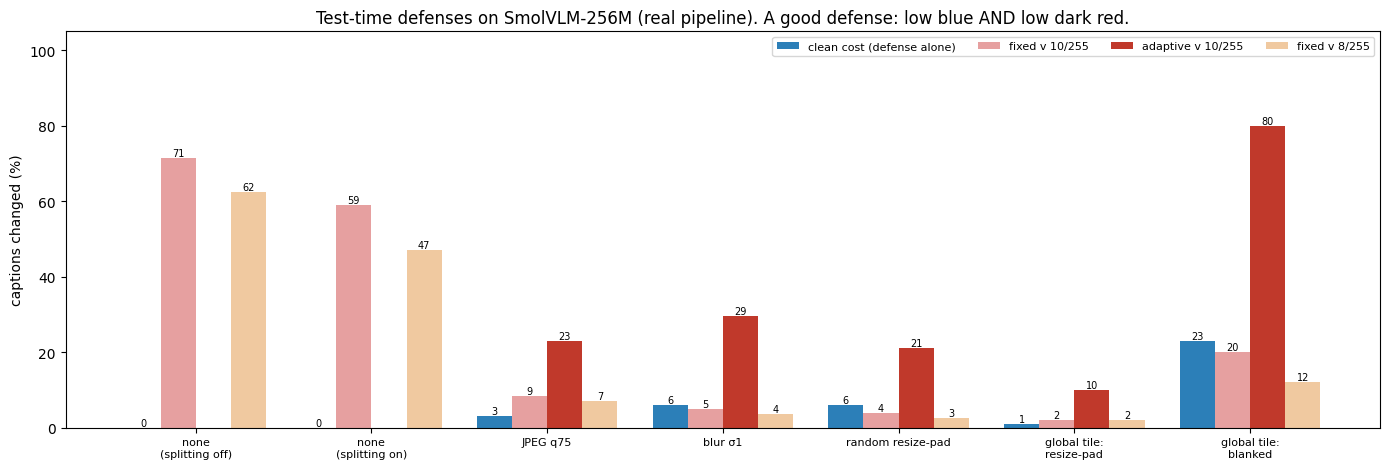

In [12]:
names = list(RES); x = np.arange(len(names)); w = 0.2
series = [("clean_cost", "clean cost (defense alone)", "#2c7fb8"), ("fixed v (10/255)", "fixed v 10/255", "#e6a0a0"),
          ("adaptive v (10/255)", "adaptive v 10/255", "#c0392b"), ("fixed v (8/255)", "fixed v 8/255", "#f0c9a0")]
fig, ax = plt.subplots(figsize=(14, 4.8))
for k, (c, lab, col) in enumerate(series):
    vals = [100 * RES[n].get(c, np.nan) for n in names]
    b = ax.bar(x + (k - 1.5) * w, vals, w, label=lab, color=col); ax.bar_label(b, fmt="%.0f", fontsize=7)
ax.set_xticks(x, [n.replace(": ", ":\n").replace(" (", "\n(") for n in names], fontsize=8)
ax.set_ylabel("captions changed (%)"); ax.set_ylim(0, 105); ax.legend(fontsize=8, ncol=4)
ax.set_title("Test-time defenses on SmolVLM-256M (real pipeline). A good defense: low blue AND low dark red.")
plt.tight_layout(); plt.savefig(OUT / "test_time_defenses.png", dpi=150); plt.show()